# Lesson 2 · The reward: what the agent is told to want

In reinforcement learning you never tell the agent *how* to move. You tell it what each
moment is worth, and training searches for behaviour that collects the most. If you know
optimal feedback control, the reward is simply the negative of the cost function.

This lesson covers:

1. every reward term and when it is paid;
2. what a trial is worth, term by term, and the "exchange rate" between terms;
3. **why the task is built so that lookahead pays off**, without the reward ever
   mentioning it (the core idea of the project);
4. the hold period;
5. reward shaping, and why only one kind is allowed;
6. how to change the reward sensibly.

Everything here uses the hand-written controllers from lesson 1, so no training is
needed.

In [1]:
from lesson_tools import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from seqreach.config import Config

use_style()

## 1 · The reward terms

Every step, the environment adds up these terms. That sum is the entire task
specification.

| term | paid when | amount | config key (`reward.*`) | default |
|---|---|---|---|---|
| target hit | an intermediate target is acquired | `+r_hit` | `r_hit` | +10 |
| final target | the last target is acquired (trial ends) | `+r_final` | `r_final` | +20 |
| false start | leaving the start before the go cue (trial ends) | `r_false_start` | `r_false_start` | −5 |
| time | every step after the go cue | `−w_time · dt` | `w_time` | 1.0 (so −0.02 per step) |
| effort | every step | `−w_effort · (u/u_max)² · dt` | `w_effort` | 0.5 |
| force change | every step | `−w_rate · ((u − u_prev)/u_max)²` | `w_rate` | 0.05 |
| hold position | every step before go | `−w_hold · x²` | `w_hold` | 20 |
| hold still | every step before go | `−w_hold_v · v²` | `w_hold_v` | 2 |
| wall | every step touching x = ±1.5 | `−w_wall` | `w_wall` | 0.1 |
| shaping | after go (section 5) | depends on the mode | `shaping`, `shaping_coef` | `"pbrs"`, 2.0 |

**Notice what is missing.** Nothing refers to a trajectory, a velocity profile, a
via-point, a reaction time, or where the *next* target is. If lookahead shows up in a
trained agent, it came from optimising this, not from being asked for.

**Where it lives:** the `# --- costs` and `# --- acquisition` blocks of
`BatchedSeqReach1D.step` in [`seqreach/env.py`](../seqreach/env.py).

In [3]:
show(Config().reward)

,value
key,
r_hit,10.0
r_final,20.0
r_false_start,-5.0
w_effort,0.5
w_rate,0.05
w_time,1.0
w_hold,20.0
w_hold_v,2.0
w_wall,0.1


## 2 · Price out one trial

**See it.** Run the hand-written controller through a three-target trial, then recompute
every term from the recorded movement. The function below is the reward formula from the
table, written out once per term. If it matches the environment's own reward step for
step, you know exactly what the environment is doing.

Shaping is switched off here; section 5 adds it back.

In [5]:
cfg = Config().override({"plant.sigma_sdn": 0.0, "reward.shaping": "none"})
targets = [0.5, -0.3, 0.2]
df, episode = run_trial(cfg, targets, pd_controller())

def reward_terms(df, cfg, n_targets):
    '''Recompute every reward term, step by step, from a recorded trial.'''
    r, p, t = cfg.reward, cfg.plant, cfg.task
    pre_go = ~df.go
    u_prev = df.u.shift(1, fill_value=0.0)           # the force on the previous step
    last = df.cur == n_targets - 1                   # reaching for the final target?
    return pd.DataFrame({
        "targets":       df.acquired * np.where(last, r.r_final, r.r_hit),
        "time":          -r.w_time * p.dt * df.go,
        "effort":        -r.w_effort * (df.u / p.u_max) ** 2 * p.dt,
        "force change":  -r.w_rate * ((df.u - u_prev) / p.u_max) ** 2,
        "hold position": -r.w_hold * (df.x - t.start_x) ** 2 * pre_go,
        "hold still":    -r.w_hold_v * df.v ** 2 * pre_go,
        "wall":          -r.w_wall * (df.x.abs() >= p.x_limit),
        "false start":   r.r_false_start * (pre_go & ((df.x - t.start_x).abs() > t.hold_abort_dist)),
    })

terms = reward_terms(df, cfg, len(targets))
print("largest step-by-step mismatch with the environment:",
      f"{(terms.sum(axis=1) - df.reward).abs().max():.1e}")
terms.sum().round(3)


largest step-by-step mismatch with the environment: 4.7e-07


targets          40.000
time             -2.040
effort           -0.562
force change     -0.232
hold position     0.000
hold still        0.000
wall              0.000
false start       0.000
dtype: float64

The mismatch is at the level of float rounding, so the formula above *is* the reward.
Here is where the total comes from, and how it builds up over the trial:

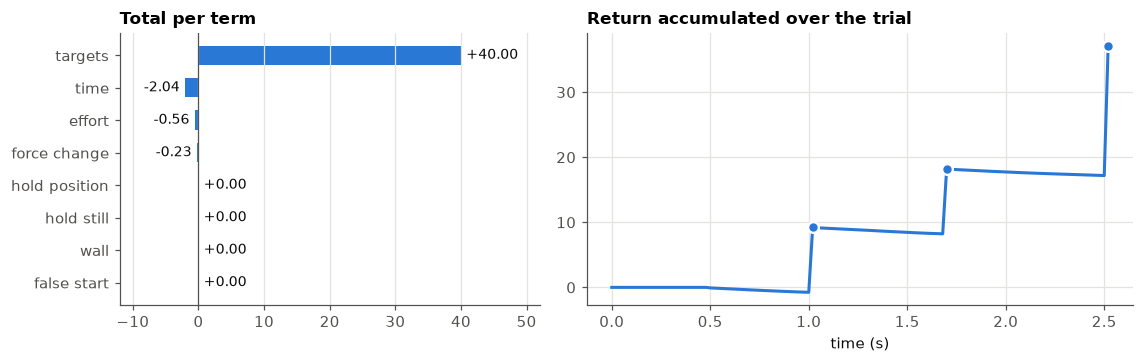

In [6]:
totals = terms.sum()
fig, (ax_b, ax_c) = plt.subplots(1, 2, figsize=(10.5, 3.4), gridspec_kw={"width_ratios": [1, 1.3]})

y = np.arange(len(totals))[::-1]
ax_b.barh(y, totals.values, color=BLUE, height=0.6)
for yi, val in zip(y, totals.values):
    ax_b.text(val + (0.8 if val >= 0 else -0.8), yi, f"{val:+.2f}", va="center",
              ha="left" if val >= 0 else "right", color=INK, fontsize=9)
ax_b.set_yticks(y, totals.index)
ax_b.axvline(0, color=INK_SOFT, lw=0.8)
ax_b.set_xlim(-12, 52)
ax_b.grid(axis="y", visible=False)
ax_b.set_title("Total per term")

ax_c.plot(df.time_s, df.reward.cumsum(), color=BLUE)
hits = df[df.acquired]
ax_c.plot(hits.time_s, df.reward.cumsum()[df.acquired], "o", color=BLUE, ms=7, mec="white", mew=1.5)
ax_c.set_xlabel("time (s)")
ax_c.set_title("Return accumulated over the trial")
plt.tight_layout()

**Reading it.** The target payoffs dominate. Time costs about 1 per second of movement,
and effort and force changes cost well under 1 each. The return climbs in three jumps
(the targets) and drifts down slowly in between (time and effort).

A useful habit is to know the **exchange rate** between terms. This table is computed
from the config, so it stays right if you change the defaults:

In [8]:
r, dt = cfg.reward, cfg.plant.dt
per_s = round(1 / dt)                     # steps per second
pd.Series({
    "hit an intermediate target":               r.r_hit,
    "hit the final target":                     r.r_final,
    "false start":                              r.r_false_start,
    "1 s of movement time (after go)":          -r.w_time * dt * per_s,
    "1 s at full force":                        -r.w_effort * 1.0 ** 2 * dt * per_s,
    "one jump from +u_max to -u_max":           -r.w_rate * 2.0 ** 2,
    "1 s pinned against the wall":              -r.w_wall * per_s,
    "1 s held 0.1 away from start (before go)": -r.w_hold * 0.1 ** 2 * per_s,
}, name="reward").to_frame()


,reward
hit an intermediate target,10.0
hit the final target,20.0
false start,-5.0
1 s of movement time (after go),-1.0
1 s at full force,-0.5
one jump from +u_max to -u_max,-0.2
1 s pinned against the wall,-5.0
1 s held 0.1 away from start (before go),-10.0


So a target is worth 10 seconds of time, and a full second at maximum force costs half as
much as a second of time. **Effort is cheap and time is expensive**, so the optimal
behaviour is to move fast and hard. The hold is strict: sitting just 0.1 from the start
before the go cue costs 10 per second. Keep this table in mind whenever you change a weight:
it tells you in advance which terms will win.

## 3 · Why the task lets lookahead pay off

This is the idea the whole repo is built on.

Suppose you had to **stop** at T1: acquisition requires staying inside the target for a
while (`task.dwell_inter = 25`, half a second). Then every trial passes through the same
state after T1: at T1, at rest. However the reach to T1 was executed, the reach to T2
starts from the same place. So nothing about T2 can make a different T1 reach better. The
best T1 reach is independent of T2, and **no amount of training can produce lookahead**.
(The design doc calls this Case A.)

Now suppose you only have to **pass through** T1 (`dwell_inter = 1`, the default). The
velocity you carry through T1 is now a free choice, and the best choice depends on where
T2 is. If T2 lies beyond T1, fly through; if T2 is behind, arrive already slowing down.
The reach to T1 *should* depend on T2. (Case B.)

For readers who like it in symbols: with pass-through acquisition, the value of the
remaining sequence depends on the exit velocity, `J*_{k+1}(T_k, v_exit; T_{k+1})`. Choosing
the reach to `T_k` means trading its own cost against that cost-to-go, so the optimal
reach is a function of `T_{k+1}`.

**See it.** Compare two hand-written controllers on a trial whose T2 lies beyond T1:

- the **stopper** (lesson 1's controller) aims to stop at each target;
- the **passer** is identical, except that while T2 lies further along the same
  direction, it aims straight at T2. It crosses T1 at speed, and its reach to T1 depends on T2.

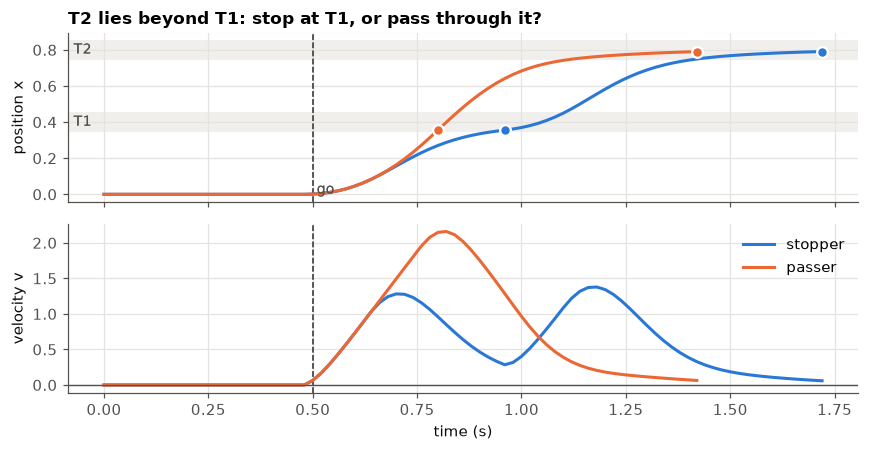

In [9]:
T = [0.4, 0.8]                          # T2 lies beyond T1, in the same direction
stop_df, stop_ep = run_trial(cfg, T, pd_controller())
pass_df, pass_ep = run_trial(cfg, T, passer_controller())

axes = plot_trial(stop_df, T, cfg, color=BLUE, label="stopper")
plot_trial(pass_df, T, cfg, axes=axes, color=ORANGE, label="passer",
           title="T2 lies beyond T1: stop at T1, or pass through it?")
axes[1].legend(loc="upper right")
plt.tight_layout()


In [10]:
def compare(results):
    rows = {}
    for name, (d, ep) in results.items():
        t1 = d[d.acquired].iloc[0]                    # the step at which T1 counted as hit
        rows[name] = {"finished": ep["success"], "time to finish (s)": ep["l"] * 0.02,
                      "speed as T1 is hit": round(t1.v, 2), "return": round(ep["r"], 3)}
    return pd.DataFrame(rows).T

print("dwell_inter = 1 (pass-through, the default)")
compare({"stopper": (stop_df, stop_ep), "passer": (pass_df, pass_ep)})

dwell_inter = 1 (pass-through, the default)


,finished,time to finish (s),speed as T1 is hit,return
stopper,True,1.74,0.28,28.331
passer,True,1.44,2.15,28.714


The passer crosses T1 at speed, finishes about 0.3 s sooner, and earns more. Now make
the same comparison with a 25-step dwell at T1:

In [11]:
cfg25 = cfg.override({"task.dwell_inter": 25})
print("dwell_inter = 25 (must stop at T1)")
compare({"stopper": run_trial(cfg25, T, pd_controller()),
         "passer":  run_trial(cfg25, T, passer_controller())})

dwell_inter = 25 (must stop at T1)


,finished,time to finish (s),speed as T1 is hit,return
stopper,True,2.22,0.02,27.87
passer,True,2.78,-0.02,27.02


With the dwell, both controllers must be at rest when T1 counts, and the passer's
overshoot now costs it time: it flies past T1, has to come back, and finishes last.
**The dwell setting decides whether looking ahead can pay at all.** That is ablation axis
C1 (`stop_at_targets` in `run_ablations.py`).

What makes passing worth it in the first place? Mostly the **time cost**. Here is how much
the passer earns over the stopper as `w_time` changes:

In [12]:
rows = []
for w_time in [0.0, 0.5, 1.0, 2.0, 5.0]:
    c = cfg.override({"reward.w_time": w_time})
    _, s = run_trial(c, T, pd_controller())
    _, p = run_trial(c, T, passer_controller())
    rows.append({"w_time": w_time, "stopper return": s["r"], "passer return": p["r"],
                 "passing earns": p["r"] - s["r"]})
pd.DataFrame(rows).set_index("w_time").round(3)


,stopper return,passer return,passing earns
w_time,,,
0.0,29.571,29.654,0.084
0.5,28.951,29.184,0.234
1.0,28.331,28.714,0.384
2.0,27.091,27.774,0.684
5.0,23.371,24.954,1.584


The more time costs, the more it is worth arriving at T1 already moving toward T2.
Nothing in the reward mentions velocity at T1 or where T2 is; the incentive falls out of
**pass-through acquisition plus a price on time**.

Two things to keep straight:

- These are *hand-written* controllers. They only show that the reward **allows** and
  **favours** lookahead. Whether a trained agent actually finds it is measured in
  lesson 4.
- The difference per trial looks small (a fraction of a point). Training averages over
  millions of steps, so consistent small differences are exactly what it picks up.

## 4 · The hold period

**The idea.** Before the go cue the agent can already see the targets but must stay put:
it pays `w_hold · x²` and `w_hold_v · v²` every step, and leaving |x| > 0.15 is a false
start (−5, trial over). The go cue comes at an unpredictable time, so the agent cannot
simply time its departure.

This mirrors the **instructed-delay** paradigm from monkey and human work. The agent knows
the plan but must wait, so its internal state during the hold can be analysed as
preparation (lesson 4 and design doc §8.4).

In [13]:
stopper = pd_controller()
controllers = {
    "still":     stopper,                                         # waits for the go cue
    "fidgety":   lambda s: 0.4 if not s["go"] else stopper(s),    # drifts gently during the hold
    "impatient": lambda s: 8.0,                                   # goes immediately
}
rows = {}
for name, ctrl in controllers.items():
    d, ep = run_trial(cfg, [0.5, -0.3], ctrl)
    tm = reward_terms(d, cfg, 2).sum()
    rows[name] = {"hold costs": tm["hold position"] + tm["hold still"],
                  "false start": tm["false start"], "trial length (steps)": ep["l"],
                  "return": ep["r"]}
pd.DataFrame(rows).T.round(3)

,hold costs,false start,trial length (steps),return
still,0.000,0.0,100.0,27.928
fidgety,-0.770,0.0,97.0,27.255
impatient,-18.258,-5.0,11.0,-23.418


A little drift costs a little. Leaving costs the trial.

**Knobs:** `reward.w_hold`, `reward.w_hold_v`, `reward.r_false_start`,
`task.hold_abort_dist`, and the hold duration `task.delay_min_s` / `task.delay_max_s`.

## 5 · Shaping: a learning aid that must not change the answer

**The problem.** Early in training the agent moves at random and rarely hits a target, so
it rarely sees a reward and has little to learn from. Shaping adds a small, frequent hint
(roughly "getting closer is good") to speed up learning.

**The danger.** A hint changes the problem if you are careless. The naive hint "pay
`−c·|x − T_current|` every step" rewards *being close to the current target at every
moment*. That is a preference about the shape of the movement, so it would amount to
implicit supervision of the very thing the project studies.

**The fix: potential-based shaping (PBRS, the default).** Define a "potential"
`Φ(s) = −c·|x − T_current|`, which is zero at the target and more negative further away,
and pay the *change* in potential:

```
F_t = γ · Φ(s_{t+1}) − Φ(s_t)
```

Summed with the agent's own discount γ over a whole trial, all the middle terms cancel,
leaving only `γ^T Φ(end) − Φ(start)`. In this environment both ends are zero (Φ is 0
before the go cue and at the end of a trial), so **every completed trial gets exactly
zero total shaping, whatever path it took**. PBRS cannot prefer one movement over another;
it only moves credit earlier in time. The γ inside the formula is what makes the
cancellation exact.

**See it.** Run the same movement with shaping off and on. The difference in reward is
the shaping term.

same movement in both runs: True
plain sum of F         = +0.2976
discounted sum of F    = +5.9e-07   <- zero, up to rounding
episode return  r      = 37.464   (includes shaping)
task return     r_task = 37.166   (shaping excluded)


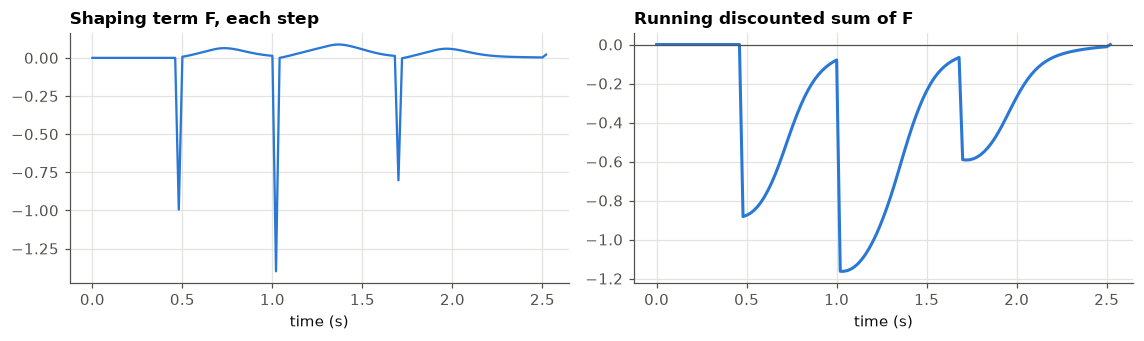

In [14]:
gamma = cfg.ppo.gamma
T3 = [0.5, -0.3, 0.2]
plain, _ = run_trial(cfg, T3, pd_controller())                                   # shaping off
shaped, ep_shaped = run_trial(cfg.override({"reward.shaping": "pbrs"}), T3, pd_controller())

F = shaped.reward.values - plain.reward.values        # the shaping term, step by step
discount = gamma ** np.arange(len(F))

print("same movement in both runs:", np.allclose(plain.x, shaped.x))
print(f"plain sum of F         = {F.sum():+.4f}")
print(f"discounted sum of F    = {(discount * F).sum():+.1e}   <- zero, up to rounding")
print(f"episode return  r      = {ep_shaped['r']:.3f}   (includes shaping)")
print(f"task return     r_task = {ep_shaped['r_task']:.3f}   (shaping excluded)")

fig, (ax_f, ax_s) = plt.subplots(1, 2, figsize=(10.5, 3.2))
ax_f.plot(shaped.time_s, F, color=BLUE, lw=1.5)
ax_f.set_title("Shaping term F, each step")
ax_s.plot(shaped.time_s, np.cumsum(discount * F), color=BLUE)
ax_s.axhline(0, color=INK_SOFT, lw=0.8)
ax_s.set_title("Running discounted sum of F")
for ax in (ax_f, ax_s):
    ax.set_xlabel("time (s)")
plt.tight_layout()

F is slightly positive while the mass closes in on a target. It dips sharply when the go
cue switches the potential on, and again at each intermediate acquisition, when the
"current target" switches to a farther one. The discounted sum ends at zero.

Why does the *plain* (undiscounted) sum not vanish? Because the cancellation needs the γ
weights. The practical consequence is that a run's logged `episodic_return` (with shaping)
sits slightly above `episodic_return_task` (without). The training log records both;
**judge progress by the task return.**

Now the naive `"greedy"` mode, which is offered only as an ablation, on the stopper and
the passer from section 3:

In [15]:
rows = {}
for name, ctrl in {"stopper": pd_controller(), "passer": passer_controller()}.items():
    base, _ = run_trial(cfg, T, ctrl)
    row = {}
    for mode in ["pbrs", "greedy"]:
        sh, _ = run_trial(cfg.override({"reward.shaping": mode}), T, ctrl)
        F = sh.reward.values - base.reward.values
        row[f"{mode}: total discounted shaping"] = (gamma ** np.arange(len(F)) * F).sum()
    rows[name] = row
pd.DataFrame(rows).T.round(4) + 0.0

,pbrs: total discounted shaping,greedy: total discounted shaping
stopper,0.0,-0.3474
passer,0.0,-0.2512


PBRS gives both movements exactly zero, so it has no opinion about how you move. Greedy
charges them different amounts, which makes it a preference about movement shape baked
into the reward. (Here it happens to favour the passer, which reaches T1 sooner. Which
way it pushes in general is not obvious, which is exactly why it is measured rather than
assumed.) That is why it exists only to *measure* the confound (the `greedy2` …
`greedy60` arms). Results doc §4 found that it does not suppress co-articulation at
strength 2.

**Knobs:** `reward.shaping` = `"pbrs"` (default), `"none"` (sparse reward), or
`"greedy"`; `reward.shaping_coef` = c.

## 6 · Changing the reward: a practical guide

| if you want… | change | what to expect | watch out for |
|---|---|---|---|
| more urgent, faster movements | raise `reward.w_time` | shorter trials, more force, more lookahead pressure (section 3) | more false starts if urgency leaks into the hold |
| gentler, smoother movements | raise `reward.w_effort`, `reward.w_rate` | lower peak forces, longer trials | past a point targets stop being worth the effort |
| to test whether effort cost matters (axis C2) | `reward.w_effort=0`, `reward.w_rate=0` | the `no_effort` arm | arrival speed stops being costly; results doc §8 |
| to force stopping at each target (axis C1) | `task.dwell_inter=25` | Case A: lookahead impossible in principle | needs a bigger time budget: `task.max_steps=700` |
| to learn from sparse reward only | `reward.shaping="none"` | slower early learning; same final behaviour | nothing else |
| a stricter hold | raise `reward.w_hold` or lower `task.hold_abort_dist` | stiller holding posture | more false starts early in training |

Four rules of thumb:

1. **Everything is one currency.** Before training with a new weight, price out a trial with
   `reward_terms` and the exchange-rate table. If one term dwarfs the rest, it will decide
   the behaviour.
2. **Only ratios matter.** Multiplying *every* term by 10 changes nothing, because the best
   behaviour is the same and training also rescales rewards internally
   (`ppo.norm_reward`). Changing one term relative to the others is what changes the
   optimum.
3. **A new reward is a new task.** Retrain (8 seeds), check competence (lesson 4), and only
   then compare against the baseline.
4. **Anything that lengthens trials needs a bigger `max_steps`.** A tight time limit makes
   learning fail by timeout, which looks like an effect but is a setup fault (results doc
   §2).

## Check yourself

**1.** You multiply every reward term and payoff by 2. Does the trained behaviour change?

<details><summary>Answer</summary>

No. Scaling the whole reward does not change which behaviour is best, and training
normalises rewards by their running scale anyway. Only the ratios between terms matter.
</details>

**2.** You set `reward.w_effort = 5`. Using the exchange-rate table, what does a second at
full force cost now, and what would you expect a trained agent to do differently?

<details><summary>Answer</summary>

5 per second, versus 1 per second of time and 10 per target. Force is now expensive
relative to time, so expect gentler, slower movements. Targets are still worth reaching,
but the speed-versus-force balance shifts toward lower force.
</details>

**3.** Why not just add a reward term like "+1 when the velocity at T1 points toward T2"?

<details><summary>Answer</summary>

Because that would put the effect in by hand. The project's claim is that lookahead
*emerges* from a reward that never mentions it; any term that describes the movement
itself would make the result circular.
</details>

**4.** With `shaping="pbrs"`, a run's `episodic_return` is higher than its
`episodic_return_task`. Is the agent doing better than the task return says?

<details><summary>Answer</summary>

No. The gap is shaping income, which cancels over a completed trial once properly
discounted. Judge the agent by task return and success rate.
</details>

**5.** Set `dwell_inter = 25` in section 3 and imagine a *trained* agent. What CI would the
Case A argument predict for the reach to T1?

<details><summary>Answer</summary>

Zero dependence on T2 at the moment of *leaving* T1, because it must be at rest there.
Careful: the repo's index measures velocity when the mass first *enters* T1's band, which
the dwell does not pin down. The results doc (§6) found a negative CI there, and discusses
whether that index tests the theory at all.
</details>

## Summary

- The reward is **payoffs** (+10, +20, −5) plus **running costs** (time, effort, force
  changes, hold, wall). Nothing describes the movement.
- **Time is expensive and effort is cheap** at the defaults: a target is worth 10 s, and a
  second at full force costs half a second of time.
- **Pass-through acquisition plus a time cost makes lookahead pay.** A dwell at each target
  makes it impossible. This is the logic behind the C1 axis (`stop_at_targets`).
- **PBRS shaping** sums to exactly zero over any completed trial, so it speeds learning
  without preferring any movement. Greedy shaping does prefer movements and exists only as
  an ablation.
- **Change weights by ratio, price them out first, and retrain before comparing.**

Next: **Lesson 3 · The agent and how it learns**.